       stazioneA    stazioneB  coefficiente r
0    stazione145  stazione123        1.000000
1     stazione12    stazione6        0.984850
2    stazione104   stazione73        0.977693
3     stazione73   stazione12        0.975962
4     stazione23   stazione12        0.975179
..           ...          ...             ...
522  stazione141  stazione101        0.701561
523  stazione137  stazione101        0.697904
524  stazione130  stazione123        0.693807
525  stazione129  stazione101        0.689951
526  stazione130  stazione129        0.688441

[527 rows x 3 columns]
       stazioneA    stazioneB  coefficiente r    Distanza
0    stazione145  stazione123        1.000000   21.247379
1     stazione12    stazione6        0.984850   17.973881
2    stazione104   stazione73        0.977693   17.309244
3     stazione73   stazione12        0.975962   27.333987
4     stazione23   stazione12        0.975179   23.298615
..           ...          ...             ...         ...
522  stazione141  

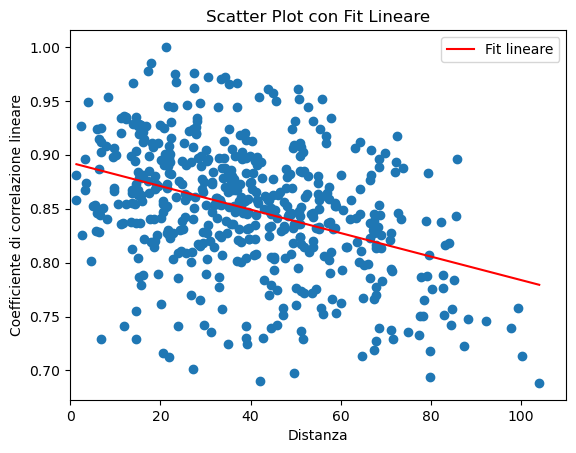

In [5]:
import geopy
import pandas as pd
import matplotlib.pyplot as plt
from geopy.distance import distance
import numpy as np
# Coordinate delle stazioni (sostituire con le coordinate reali)
coordinates = {
    'stazione2': (44.64, 7.99),  # Esempio di coordinate per New York City
    'stazione4': (44.58,7.57),  # Esempio di coordinate per Los Angeles
    'stazione6': (44.75, 8.39),  # Esempio di coordinate per New York City
    'stazione12': (44.79, 8.17),  # Esempio di coordinate per Los Angeles
    'stazione23': (44.63, 7.98),  # Esempio di coordinate per New York City
    'stazione30': (44.58, 8.14),  # Esempio di coordinate per Los Angeles
    'stazione65': (44.61, 7.50),  # Esempio di coordinate per New York City
    'stazione73': (44.96, 7.92),  # Esempio di coordinate per Los Angeles
    'stazione83': (44.98, 8.45),  # Esempio di coordinate per New York City
    'stazione89': (45.07,7.59),
    'stazione101': (44.51,8.05),  # Esempio di coordinate per Los Angeles
    'stazione104': (45.08, 8.06),  # Esempio di coordinate per New York City
    'stazione119': (44.76, 7.90),  # Esempio di coordinate per Los Angeles
    'stazione123': (44.61, 7.58),  # Esempio di coordinate per New York City
    'stazione124': (44.77, 7.32),  # Esempio di coordinate per Los Angeles
    'stazione125': (44.67, 7.56),  # Esempio di coordinate per New York City
    'stazione126': (44.64, 8.02),  # Esempio di coordinate per Los Angeles
    'stazione127': (44.77, 7.97),  # Esempio di coordinate per New York City
    'stazione128': (44.57,7.76),  # Esempio di coordinate per Los Angeles
    'stazione129': (44.37,7.56),  # Esempio di coordinate per New York City
    'stazione130': (45.22,8.11),  # Esempio di coordinate per Los Angeles
    'stazione131': (44.56,7.64),  # Esempio di coordinate per New York City
    'stazione133': (44.47,7.78 ),  # Esempio di coordinate per Los Angeles
    'stazione134': (44.82,8.13 ),  # Esempio di coordinate per New York City
    'stazione135': (44.68,8.15),  # Esempio di coordinate per Los Angeles
    'stazione136': (44.46, 8.10),  # Esempio di coordinate per New York City
    'stazione137': (44.46,7.43),  # Esempio di coordinate per Los Angeles
    'stazione138': (44.59, 7.95),  # Esempio di coordinate per New York City
    'stazione139': (44.76, 8.40),  # Esempio di coordinate per Los Angeles
    'stazione140': (44.62, 7.95),  # Esempio di coordinate per New York City
    'stazione141': (44.74, 8.17),  # Esempio di coordinate per Los Angeles
    'stazione143': (44.69, 8.07),  # Esempio di coordinate per New York City
    'stazione145': (44.8, 7.55),  # Esempio di coordinate per Los Angeles
   
}

# Funzione per calcolare la distanza tra due stazioni sulla Terra
def calculate_distance(station1, station2):
    coord1 = coordinates[station1]
    coord2 = coordinates[station2]
    return distance(coord1, coord2).kilometers

df = pd.read_csv(r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\corlin\coefficienti_correlazione_ordinati.csv', header=0,sep=';')
# Calcolo delle distanze e aggiunta alla correlazione
print(df)
# Lista delle distanze
distanze = []

# Calcolo delle distanze e aggiunta alla lista
for index, row in df.iterrows():
    stazione1 = row['stazioneA']
    stazione2 = row['stazioneB']
    distanza = calculate_distance(stazione1, stazione2)
    distanze.append(distanza)

# Aggiungi la lista delle distanze come nuova colonna al DataFrame
df['Distanza'] = distanze
            
print(df)
df.to_csv(r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\corlin\corlindistanza.csv')

# Plot dei dati
plt.scatter(df['Distanza'], df['coefficiente r'])

# Aggiungi etichette agli assi
plt.xlabel('Distanza')
plt.ylabel('Coefficiente di correlazione lineare')




 #Calcola i coefficienti del polinomio di grado 1 (fit lineare)
coefficients = np.polyfit(df['Distanza'], df['coefficiente r'], 1)

# Crea la funzione polinomiale
poly_function = np.poly1d(coefficients)

# Crea un array di valori x per tracciare la linea di regressione
x_values = np.linspace(min(df['Distanza']), max(df['Distanza']), 100)

# Calcola i valori y corrispondenti utilizzando la funzione polinomiale
y_values = poly_function(x_values)



# Plot della linea di regressione
plt.plot(x_values, y_values, color='red', label='Fit lineare')

plt.xlim(0,110)
# Aggiungi un titolo al grafico
plt.title('Scatter Plot con Fit Lineare')

# Aggiungi una legenda
plt.legend()

# Mostra il grafico
plt.show()
